In [2]:
#  Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib 
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score,recall_score,
    f1_score, roc_auc_score,confusion_matrix,
    classification_report
)


In [5]:
# Load Dataset

df = pd.read_csv(r"C:\Users\Admin\Desktop\Salon AppointmentCancellation Prediction(ML)\chennai_salon_appointments_synthetic(dataset).csv")
df.head()

,booking_id,salon_name,area,city,customer_id,service,service_price_inr,staff_member,booking_date,appointment_date,days_in_advance,booking_channel,appointment_status,cancelled_by,cancellation_reason
0,CHN100001,Urban Trim,Chromepet,Chennai,CUST1333,Pedicure,570,Stylist_18,2025-02-28,2025-03-01,1,WhatsApp,Completed,Not applicable,Not applicable
1,CHN100002,Classic Cuts,Tambaram,Chennai,CUST1288,Waxing,1070,Stylist_10,2025-03-25,2025-03-27,2,Phone,Completed,Not applicable,Not applicable
2,CHN100003,Style Studio,T. Nagar,Chennai,CUST1323,Pedicure,750,Stylist_18,2026-08-01,2026-08-10,9,Instagram,Cancelled,Customer,Changed plans
3,CHN100004,Chennai Hair Lounge,Tambaram,Chennai,CUST1240,Pedicure,1180,Stylist_17,2025-01-29,2025-02-04,6,Website,Completed,Not applicable,Not applicable
4,CHN100005,Glow & Go Salon,Anna Nagar,Chennai,CUST1499,Manicure,660,Stylist_15,2025-10-28,2025-10-30,2,WhatsApp,Completed,Not applicable,Not applicable


In [6]:
#  DATA UNDERSTANDING

df.shape

(1500, 15)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   booking_id           1500 non-null   object
 1   salon_name           1500 non-null   object
 2   area                 1500 non-null   object
 3   city                 1500 non-null   object
 4   customer_id          1500 non-null   object
 5   service              1500 non-null   object
 6   service_price_inr    1500 non-null   int64 
 7   staff_member         1500 non-null   object
 8   booking_date         1500 non-null   object
 9   appointment_date     1500 non-null   object
 10  days_in_advance      1500 non-null   int64 
 11  booking_channel      1500 non-null   object
 12  appointment_status   1500 non-null   object
 13  cancelled_by         1500 non-null   object
 14  cancellation_reason  1500 non-null   object
dtypes: int64(2), object(13)
memory usage: 175.9+ KB


In [8]:
df.describe().sum()

service_price_inr    25347.340181
days_in_advance       1552.693003
dtype: float64

In [9]:
#  DATA CLEANING

print("\nMissing Values:",df.isnull().sum().sum())


Missing Values: 0


In [10]:
print("Columns:")
print(df.columns.tolist())

Columns:
['booking_id', 'salon_name', 'area', 'city', 'customer_id', 'service', 'service_price_inr', 'staff_member', 'booking_date', 'appointment_date', 'days_in_advance', 'booking_channel', 'appointment_status', 'cancelled_by', 'cancellation_reason']


In [11]:
print(df["appointment_status"].value_counts())

appointment_status
Completed    1161
Cancelled     261
No-show        78
Name: count, dtype: int64


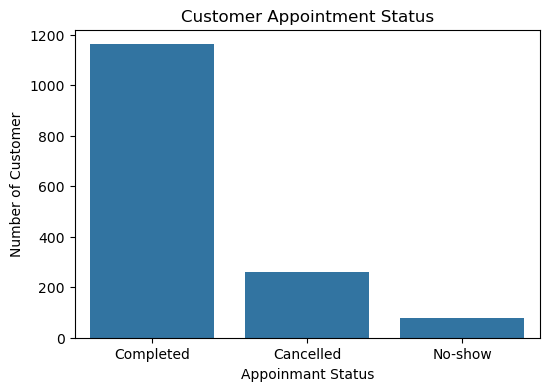

In [12]:
# chart 1 - Attrition Count

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="appointment_status")
plt.title("Customer Appointment Status")
plt.xlabel("Appoinmant Status")
plt.ylabel("Number of Customer")
plt.show()

In [20]:
# Target column

df.columns = df.columns.str.strip().str.lower()
df = df[
    df["appointment_status"].isin(["Completed","Cancelled"])
].copy()
df["target"] = (
    df["appointment_status"].str.lower() == "cancelled"
).astype(int)

print(df["target"].value_counts())

target
0    1161
1     261
Name: count, dtype: int64


In [21]:
# Unwanted columns remove

drop_columns = [
    "appointment_status",
    "cancellation_reason",
    "booking_id",
    "customer_id",
    "target"
]

x = df.drop(
    columns = [c for c in drop_columns if c in df.columns]
)

y = df["target"]

print("Features:", x.shape)
print("Target :", y.shape)

Features: (1422, 11)
Target : (1422,)


In [22]:
#  TRAIN TEST SPLIT 

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

Training data: (1137, 11)
Testing data: (285, 11)


In [23]:
# Preprocessing

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object","category","bool"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

 

In [24]:
# MODEL TRAINING

models = {
    "Logistic Regression" : LogisticRegression(max_iter=1000),
    "Decision Tree" : DecisionTreeClassifier(random_state=42),
    "Random Forest" : RandomForestClassifier(random_state=42),
    "Gradient Boosting" : GradientBoostingClassifier(random_state=42),
    "KNN" : KNeighborsClassifier(),
    "SVM" : SVC(probability = True, random_state=42),
    "Extra Trees" : ExtraTreesClassifier(random_state=42)
}

In [46]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    cv_scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=5, scoring="f1"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "CV F1 Score": cv_scores.mean()
    })

    trained_models[name] = pipeline

print("All models trained successfully!")

All models trained successfully!


In [47]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,CV F1 Score
0,Logistic Regression,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
1,Decision Tree,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
2,Random Forest,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
3,Gradient Boosting,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
6,Extra Trees,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
5,SVM,0.996491,1.0,0.980769,0.990291,0.999917,0.987593
4,KNN,0.936842,1.0,0.653846,0.790698,0.994553,0.829024


In [49]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best CV F1 Score:", results_df.iloc[0]["CV F1 Score"])

Best Model: Logistic Regression
Best CV F1 Score: 1.0


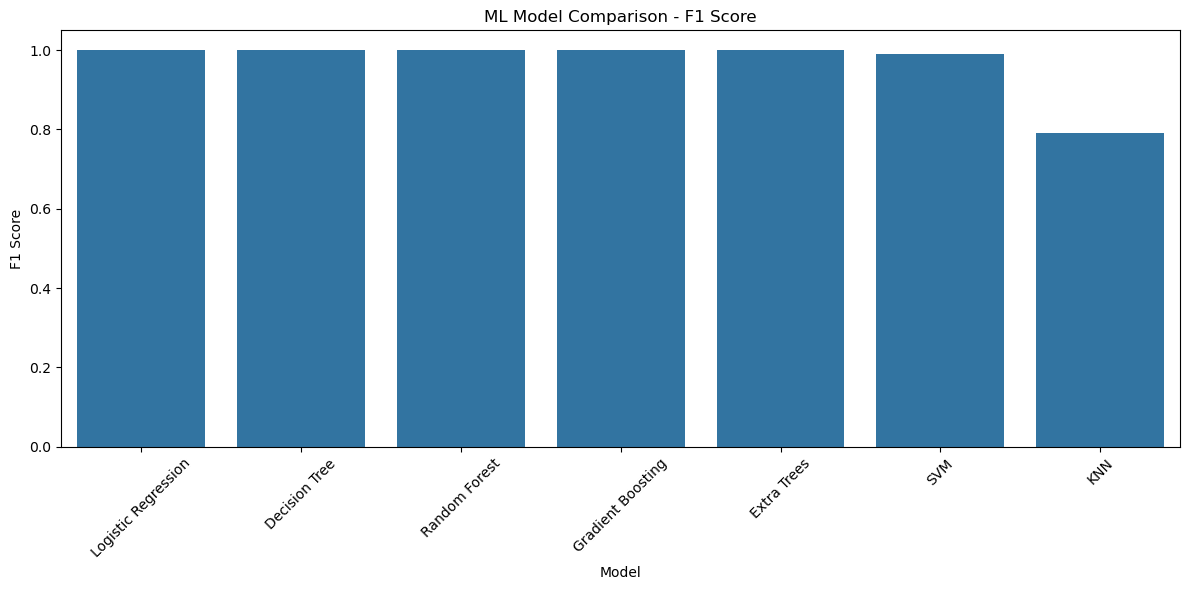

In [50]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("ML Model Comparison - F1 Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
# Best Model Evaluation

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)


Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       233
           1       1.00      1.00      1.00        52

    accuracy                           1.00       285
   macro avg       1.00      1.00      1.00       285
weighted avg       1.00      1.00      1.00       285



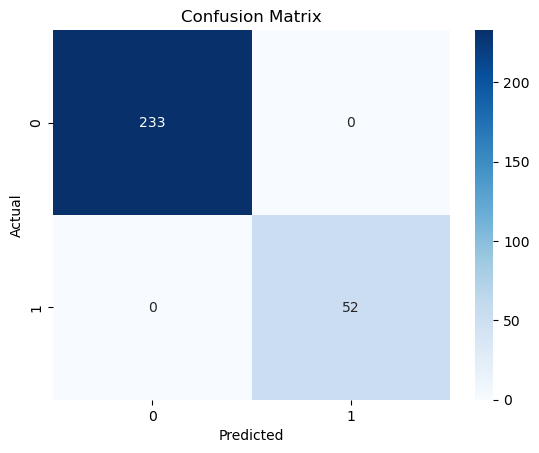

In [53]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [57]:
# Save model

joblib.dump(best_model, "best_cancellation_model.pkl")
print("Best model saved successfully!")

Best model saved successfully!


In [61]:
# Get one sample booking from test data
sample = X_test.iloc[[0]]

# Predict appointment status
prediction = best_model.predict(sample)[0]

# Get cancellation probability
probability = best_model.predict_proba(sample)[0][1]

if prediction == 1:
    print("Prediction: Appointment Cancelled")
else:
    print("Prediction: Appointment Completed")

print("Cancellation Probability:", round(probability * 100, 2), "%")

Prediction: Appointment Completed
Cancellation Probability: 0.56 %
